# 历史多任务对照：从原始任务表重新计算成绩

目标：将已有厨房16任务、每任务50回合的两模型对照，从汇总表改为可逐步复算的课程。输入为随课程保留的官方匹配记录；输出为任务覆盖检查、逐任务对照、总成功率与差值图。先人为制造重复任务故障，再验证检查函数拒绝错误，最后复算真实档案。

这是已有完整多任务推理的整理；不把新单任务训练的20种子成绩并入历史800回合。


In [1]:
from pathlib import Path
import json,copy,hashlib,tempfile,os,sys
import numpy as np
from IPython.display import display,Markdown
TOPIC=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"code/amd_benchmarks").is_dir())
EVIDENCE=TOPIC/"notebooks/results"
print("只复算已有记录和小型故障夹具，不重跑训练、评估或空间清理。")


只复算已有记录和小型故障夹具，不重跑训练、评估或空间清理。


## 1. 展开协议与每个任务的计数

先确定任务集合和每任务回合数，再统计分母。该快照记录两模型复用相同任务目录，当前文件是任务级统计；逐种子配对需要原回合文件，不能仅凭总成功率推断哪些种子被改善。


In [2]:
record=json.loads((TOPIC/"reproducibility/showcase/robocasa-official-match.json").read_text())
print(record["protocol"])
for model,data in record["models"].items():
    print(model,data["checkpoint"],"任务数",len(data["tasks"]))


{'split': 'pretrain', 'tasks': ['ArrangeTea', 'CloseFridge', 'CloseToasterOvenDoor', 'CoffeeSetupMug', 'DeliverStraw', 'OpenCabinet', 'OpenDrawer', 'PackIdenticalLunches', 'PickPlaceDrawerToCounter', 'PortionHotDogs', 'PrepareCoffee', 'RecycleBottlesByType', 'RinseSinkBasin', 'ScrubCuttingBoard', 'SeparateFreezerRack', 'SlideDishwasherRack'], 'episodes_per_task': 50, 'videos': True, 'note': 'Pi0.5 and GR00T use the same task directories produced by the completed GR00T official run.'}
gr00t robocasa/robocasa365_checkpoints:gr00t_n1-5_multitask_120000 任务数 16
pi05 robocasa/robocasa365_checkpoints:pi05_pretrain_human300_multitask_75000 任务数 16


## 2. 直接实现统计守卫

重复任务、缺任务、额外任务、错误分母、成功数越界都明确报错。汇总结果还要与文件中已公布的总数一致。


In [3]:
def validate_task_table(rows,protocol):
    tasks=[row["task"] for row in rows]
    if len(tasks)!=len(set(tasks)): raise ValueError("Duplicate task rows")
    if set(tasks)!=set(protocol["tasks"]): raise ValueError("Missing or extra tasks")
    expected=protocol["episodes_per_task"]
    for row in rows:
        if type(row["episodes"]) is not int or row["episodes"]!=expected:
            raise ValueError("Episode denominator differs from protocol")
        if type(row["successes"]) is not int or not 0<=row["successes"]<=row["episodes"]:
            raise ValueError("Invalid success count")
    episodes=sum(row["episodes"] for row in rows)
    successes=sum(row["successes"] for row in rows)
    return {"episodes":episodes,"successes":successes,"success_rate":successes/episodes}


## 3. 故障复现与修复验证

重复一行会让分母和成功数一起增大，比例看起来仍合理。这里故意追加一行，确认守卫能拦住，再用原表通过检查。


In [4]:
first=next(iter(record["models"].values()))
broken=copy.deepcopy(first["tasks"]);broken.append(copy.deepcopy(broken[0]))
try: validate_task_table(broken,record["protocol"])
except ValueError as exc: print("预期拒绝：",exc)
else: raise AssertionError("Duplicate task must fail")
for model,data in record["models"].items():
    actual=validate_task_table(data["tasks"],record["protocol"])
    assert actual["episodes"]==data["episodes"]==800
    assert actual["successes"]==data["successes"]
    assert np.isclose(actual["success_rate"],data["success_rate"])
    print(model,actual)


预期拒绝： Duplicate task rows
gr00t {'episodes': 800, 'successes': 230, 'success_rate': 0.2875}
pi05 {'episodes': 800, 'successes': 142, 'success_rate': 0.1775}


## 4. 逐任务对照，不只看总平均

每个任务的分母均为50；先按任务名连接，再计算两模型差异。若任务分母不同，必须分别报告加权总体和任务平均，不能混用。


| 任务 | gr00t | pi05 | 第二组减第一组 |
|---|---:|---:|---:|
|ArrangeTea|4/50|0/50|-4|
|CloseFridge|39/50|15/50|-24|
|CloseToasterOvenDoor|24/50|6/50|-18|
|CoffeeSetupMug|14/50|0/50|-14|
|DeliverStraw|1/50|0/50|-1|
|OpenCabinet|32/50|20/50|-12|
|OpenDrawer|20/50|25/50|+5|
|PackIdenticalLunches|7/50|1/50|-6|
|PickPlaceDrawerToCounter|19/50|31/50|+12|
|PortionHotDogs|3/50|0/50|-3|
|PrepareCoffee|0/50|0/50|+0|
|RecycleBottlesByType|1/50|9/50|+8|
|RinseSinkBasin|17/50|0/50|-17|
|ScrubCuttingBoard|26/50|2/50|-24|
|SeparateFreezerRack|1/50|0/50|-1|
|SlideDishwasherRack|22/50|33/50|+11|

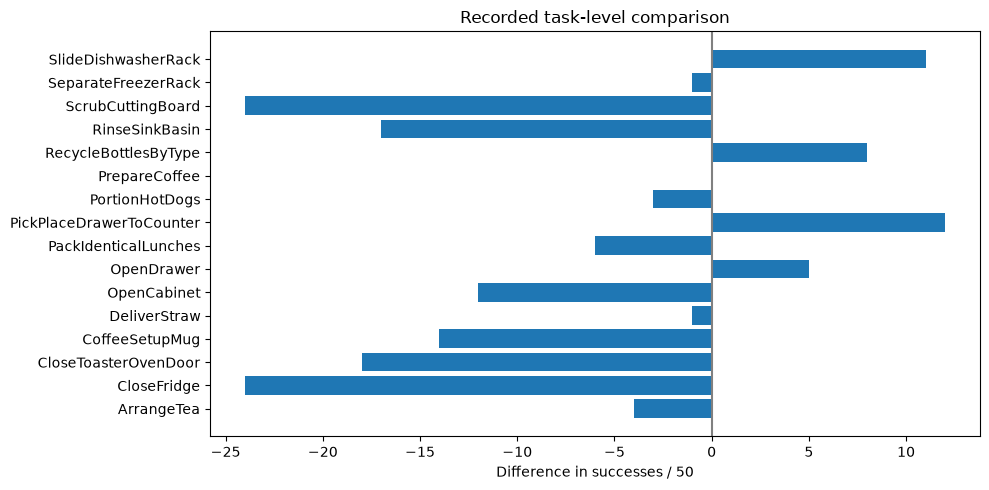

In [5]:
models=list(record["models"])
a,b=({row["task"]:row for row in record["models"][name]["tasks"]} for name in models)
lines=["| 任务 | "+models[0]+" | "+models[1]+" | 第二组减第一组 |","|---|---:|---:|---:|"]
delta=[]
for task in record["protocol"]["tasks"]:
    change=b[task]["successes"]-a[task]["successes"]
    delta.append(change)
    lines.append(f'|{task}|{a[task]["successes"]}/50|{b[task]["successes"]}/50|{change:+d}|')
display(Markdown("\n".join(lines)))
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(10,5));ax.barh(record["protocol"]["tasks"],delta);ax.axvline(0,color="grey");ax.set(xlabel="Difference in successes / 50",title="Recorded task-level comparison");fig.tight_layout();plt.show();plt.close(fig)


## 5. 与新训练结果正确衔接

17号保存的是新单任务训练及同种子20回合对照；本篇是历史16任务800回合推理。两者分别绑定权重、任务集合、分母与视频。历史录像在厨房任务入口按来源展示，新训练录像在17号中直接内嵌；不把两种实验合成一个训练提升数字。

- [厨房任务与历史录像](00_任务入口与已记录结果.ipynb)
- [真实单任务训练、评估与内嵌视频](17_robocasa365_amd_train_eval.ipynb)
